# Task 3.1 | Q3 KPI snapshot

## Q3 KPI summary

> **KPI snapshot (Q3, Jul–Sep):** signups, activation rate, monthly active users, deposit volume, loans disbursed, loan default rate (DPD30), Plus subscribers. Is the 59M deposits headline right? If not, what is, and why the gap?

**Q3 deposits were EGP 19,893,500.** The ~EGP 59M headline matches the raw successful deposit total of EGP 59,477,600 in UTC. Removing exact copies reduced it by EGP 991,800. Keeping valid non-QA users reduced it by another EGP 38,590,000. Applying the Cairo reporting window reduced it by EGP 2,300. The cleaned figure includes EGP 10,297,000 across 89 deposits on September 3.

| KPI | Result | Definition |
|---|---:|---|
| Signups | 6,191 | Cleaned users with a Q3 Cairo signup |
| Activation | 2,357 / 6,191 (38.07%) | KYC verified by extract and a successful deposit within seven days of signup |
| Monthly active users | Jul 702, Aug 1,391, Sep 2,048 | Unique users with a successful transaction of any type in the Cairo month |
| Deposit volume | EGP 19,893,500 | Successful, deduplicated deposits from valid non-QA users |
| Loans disbursed | 1,310 (EGP 1,715,500 principal) | Q3 disbursals |
| Mature DPD30 | 76 / 1,040 (7.31%) | Loans still short at due date plus 30 days among those that reached that date by Nov 5. Another 270 were immature. |
| Lucky Plus subscribers | 93 | Unique subscribers with a subscription overlapping Q3. End date is the first inactive day. |


**Follow-up with the data owners.** 
I’d confirm how the EGP 59M was calculated and trace how the 30 apparent QA accounts entered the reporting extract. For future reporting, I’d ask the team to maintain an explicit test-account flag or registry and apply that exclusion consistently across production metrics. I’d also trace the 577 extra transaction rows to the source export or ingestion step. If they came from replayed records, I’d make ingestion safe to rerun so the same txn_id is loaded once. If rows with the same ID disagree, I’d flag them for review.


In [1]:
from pathlib import Path

import pandas as pd
from sqlalchemy import create_engine

ROOT = next(folder for folder in (Path.cwd(), Path.cwd().parent) if (folder / "data").is_dir())
CLEANED = ROOT / "data" / "cleaned"
Q3_START = "2026-07-01"
Q3_END = "2026-10-01"
EXTRACT_DATE = "2026-11-05"
CAIRO_OFFSET = pd.Timedelta(hours=2)

In [12]:
# Load cleaned data into pandas DataFrames 
users = pd.read_csv(CLEANED / "users.csv", parse_dates=["signup_ts", "kyc_verified_ts"])
transactions = pd.read_csv(CLEANED / "transactions.csv", parse_dates=["txn_ts"])
loans = pd.read_csv(CLEANED / "loans.csv")
plus = pd.read_csv(CLEANED / "plus_subscriptions.csv")
deposit_audit = pd.read_csv(CLEANED / "q3_deposit_audit.csv")
print("Read cleaned data into pandas DataFrames")

# Add Converted Cairo Time column 
users["signup_cairo"] = users["signup_ts"] + CAIRO_OFFSET
transactions["txn_cairo"] = transactions["txn_ts"] + CAIRO_OFFSET
report_dates = pd.DataFrame({
    "q3_start": [Q3_START],
    "q3_end": [Q3_END],
    "extract_date": [EXTRACT_DATE],
})
print("UTC +2 Cairo time column added to users and transactions tables")

engine = create_engine("sqlite://")
users.to_sql("users", engine, index=False)
transactions.to_sql("transactions", engine, index=False)
loans.to_sql("loans", engine, index=False)
plus.to_sql("plus", engine, index=False)
deposit_audit.to_sql("deposit_audit", engine, index=False)
report_dates.to_sql("report_dates", engine, index=False)


print(f"Data loaded into in-memory SQLite database")
print()
%load_ext sql
%sql engine
print()

Read cleaned data into pandas DataFrames
UTC +2 Cairo time column added to users and transactions tables
Data loaded into in-memory SQLite database

The sql extension is already loaded. To reload it, use:
  %reload_ext sql



In [13]:
%%sql
-- Signups: one clean user row per Q3 Cairo signup.

SELECT COUNT(*) AS q3_signups
FROM users 
CROSS JOIN report_dates
WHERE signup_cairo >= q3_start AND signup_cairo < q3_end;

Running query in 'sqlite://'

q3_signups
6191


In [5]:
%%sql
-- Check deposits at or after signup, up to and including seven days later.
-- EXISTS counts each verified signup once even when several deposits qualify.

WITH signup_cohort AS (
    SELECT users.*, extract_date
    FROM users CROSS JOIN report_dates
    WHERE signup_cairo >= q3_start AND signup_cairo < q3_end
),
activation AS (
    SELECT user_id,
           CASE WHEN kyc_verified_ts < DATE(extract_date, '+1 day')
                AND EXISTS (
                    SELECT 1
                    FROM transactions AS t
                    WHERE t.user_id = signup_cohort.user_id
                      AND t.txn_type = 'deposit'
                      AND t.status = 'success'
                      AND t.txn_ts >= signup_cohort.signup_ts
                      AND STRFTIME('%Y-%m-%d %H:%M:%f', t.txn_ts)
                          <= STRFTIME('%Y-%m-%d %H:%M:%f', signup_cohort.signup_ts, '+7 days')
                ) THEN 1 ELSE 0 END AS is_activated
    FROM signup_cohort
)
SELECT COUNT(*) AS signups,
       SUM(is_activated) AS activated_users,
       ROUND(100.0 * SUM(is_activated) / COUNT(*), 2) AS activation_rate_pct
FROM activation;

Running query in 'sqlite://'

signups,activated_users,activation_rate_pct
6191,2357,38.07


In [6]:
%%sql
-- MAU: distinct users with a successful transaction of any type in the month.

SELECT STRFTIME('%Y-%m', txn_cairo) AS month,
       COUNT(DISTINCT user_id) AS monthly_active_users
FROM transactions CROSS JOIN report_dates
WHERE status = 'success'
  AND txn_cairo >= q3_start AND txn_cairo < q3_end
GROUP BY month
ORDER BY month;

Running query in 'sqlite://'

month,monthly_active_users
2026-07,702
2026-08,1391
2026-09,2048


In [7]:
%%sql
-- Notebook 00 supplies the raw UTC comparison.
WITH clean_q3_deposits AS (
    SELECT transactions.*
    FROM transactions CROSS JOIN report_dates
    WHERE txn_type = 'deposit' AND status = 'success'
      AND txn_cairo >= q3_start AND txn_cairo < q3_end
),
bridge AS (
    SELECT step, scope, deposits, volume_egp FROM deposit_audit
    UNION ALL
    SELECT 5, 'Apply Cairo calendar', COUNT(*), SUM(amount_egp) FROM clean_q3_deposits
    UNION ALL
    SELECT 6, 'September 3 concentration', COUNT(*), SUM(amount_egp)
    FROM clean_q3_deposits WHERE DATE(txn_cairo) = '2026-09-03'
)
SELECT scope, deposits, volume_egp,
       CASE WHEN step < 6 THEN volume_egp - LAG(volume_egp) OVER (ORDER BY step) END AS change_egp
FROM bridge
ORDER BY step;

Running query in 'sqlite://'

scope,deposits,volume_egp,change_egp
"Raw UTC, all statuses",9131,61044000.0,None
"Raw UTC, successful",7782,59477600.0,-1566400.0
Remove exact copies,7671,58485800.0,-991800.0
Keep valid non-QA users,7001,19895800.0,-38590000.0
Apply Cairo calendar,6995,19893500.0,-2300.0
September 3 concentration,89,10297000.0,None


In [8]:
%%sql
-- Disbursements: count loans and sum principal across the Q3 disbursal cohort.

SELECT COUNT(*) AS loans_disbursed, SUM(principal_egp) AS principal_disbursed_egp
FROM loans CROSS JOIN report_dates
WHERE disbursed_date >= q3_start AND disbursed_date < q3_end;

Running query in 'sqlite://'

loans_disbursed,principal_disbursed_egp
1310,1715500


In [9]:
%%sql
-- Use the supplied date fields. Q3 selects disbursals and November 5 sets maturity.

WITH q3_loans AS (
    SELECT loans.*, extract_date, DATE(due_date, '+30 days') AS dpd30_date,
           principal_egp + fee_egp AS total_due_egp
    FROM loans CROSS JOIN report_dates
    WHERE disbursed_date >= q3_start AND disbursed_date < q3_end
),
loan_flags AS (
    SELECT *,
           amount_repaid_egp >= total_due_egp - 0.01 AS fully_paid,
           last_repayment_date > dpd30_date AS last_payment_after_dpd30,
           dpd30_date <= extract_date AS matured
    FROM q3_loans
),
loan_outcomes AS (
    SELECT loan_id, matured,
           CASE
               WHEN NOT matured THEN 'Immature'
               WHEN NOT fully_paid THEN 'Default, still short at extract'
               WHEN last_payment_after_dpd30 THEN 'Default, later fully repaid'
               ELSE 'Fully paid by DPD30'
           END AS outcome
    FROM loan_flags
)
SELECT COUNT(*) AS loans_disbursed,
       SUM(matured) AS mature_loans,
       SUM(outcome = 'Immature') AS immature_loans,
       SUM(outcome = 'Fully paid by DPD30') AS fully_paid_by_dpd30,
       SUM(outcome = 'Default, later fully repaid') AS default_later_repaid,
       SUM(outcome = 'Default, still short at extract') AS default_still_short,
       SUM(outcome LIKE 'Default,%') AS dpd30_defaults,
       ROUND(100.0 * SUM(outcome LIKE 'Default,%') / SUM(matured), 2) AS dpd30_rate_pct
FROM loan_outcomes;

Running query in 'sqlite://'

loans_disbursed,mature_loans,immature_loans,fully_paid_by_dpd30,default_later_repaid,default_still_short,dpd30_defaults,dpd30_rate_pct
1310,1040,270,964,0,76,76,7.31


In [10]:
%%sql
SELECT COUNT(DISTINCT plus.user_id) AS unique_plus_subscribers_during_q3
FROM plus
CROSS JOIN report_dates
WHERE plus.plus_start_date < q3_end
  AND (plus.plus_end_date IS NULL OR plus.plus_end_date > q3_start);

Running query in 'sqlite://'

unique_plus_subscribers_during_q3
93


In [ ]:
%%sql
-- investigate the September 3 deposit concentration. The audit file shows 1,000 deposits on that day, but the raw data shows 1,001. This query returns the extra deposit.
SELECT t.user_id,
       u.full_name,
       u.signup_ts AS signup_utc,
       u.kyc_verified_ts AS kyc_verified_utc,
       t.txn_id,
       t.txn_cairo,
       t.status,
       t.amount_egp,
       COUNT(*) OVER (PARTITION BY t.user_id) AS deposits_by_user_that_day,
       SUM(t.amount_egp) OVER (PARTITION BY t.user_id) AS user_day_volume_egp
FROM transactions AS t
LEFT JOIN users AS u ON u.user_id = t.user_id
WHERE t.txn_type = 'deposit'
  AND t.status = 'success'
  AND t.txn_cairo >= '2026-09-03'
  AND t.txn_cairo <  '2026-09-04'
ORDER BY t.user_id, t.txn_cairo, t.txn_id;

Running query in 'sqlite://'

user_id,full_name,signup_utc,kyc_verified_utc,txn_id,txn_cairo,status,amount_egp,deposits_by_user_that_day,user_day_volume_egp
100002,منى إبراهيم,2026-07-11 16:38:41.000000,2026-07-13 16:14:03.000000,5000006,2026-09-03 22:36:34.000000,success,100000.0,1,100000.0
100159,سارة عماد,2026-07-17 20:51:26.000000,2026-07-19 10:08:16.000000,5001571,2026-09-03 00:14:00.000000,success,1000.0,1,1000.0
100284,كريم عماد,2026-07-06 20:18:44.000000,2026-07-07 08:34:14.000000,5002795,2026-09-03 16:37:51.000000,success,200000.0,1,200000.0
100458,يوسف جمال,2026-07-21 16:07:39.000000,2026-07-23 06:49:39.000000,5004397,2026-09-03 22:28:15.000000,success,200000.0,1,200000.0
100564,شريف سامي,2026-07-20 11:57:39.000000,2026-07-22 13:17:04.000000,5005171,2026-09-03 15:26:32.000000,success,100000.0,1,100000.0
100579,عمر عبد الله,2026-07-20 16:55:22.000000,2026-07-22 03:11:29.000000,5005356,2026-09-03 20:25:40.000000,success,100000.0,1,100000.0
100892,سارة فؤاد,2026-07-03 00:58:19.000000,2026-07-09 23:32:15.000000,5008464,2026-09-03 09:13:16.000000,success,30000.0,1,30000.0
100936,يوسف فتحي,2026-07-24 07:43:26.000000,2026-07-26 13:41:04.000000,5008880,2026-09-03 18:02:03.000000,success,200000.0,1,200000.0
101070,محمد علي,2026-07-22 15:37:07.000000,2026-07-26 03:55:15.000000,5010167,2026-09-03 20:29:13.000000,success,30000.0,1,30000.0
101084,مريم جمال,2026-07-20 23:31:33.000000,2026-07-22 19:54:46.000000,5010294,2026-09-03 18:12:50.000000,success,100000.0,1,100000.0


In [ ]:
%%sql
-- Rank Q3 Cairo days by successful deposit volume.
WITH daily_deposits AS (
    SELECT DATE(t.txn_cairo) AS deposit_day,
           COUNT(*) AS deposits,
           COUNT(DISTINCT t.user_id) AS depositors,
           SUM(t.amount_egp) AS deposit_volume_egp
    FROM transactions AS t
    CROSS JOIN report_dates AS r
    WHERE t.txn_type = 'deposit'
      AND t.status = 'success'
      AND t.txn_cairo >= r.q3_start
      AND t.txn_cairo <  r.q3_end
    GROUP BY DATE(t.txn_cairo)
)
SELECT deposit_day,
       deposits,
       depositors,
       deposit_volume_egp,
       ROUND(100.0 * deposit_volume_egp
             / NULLIF(SUM(deposit_volume_egp) OVER (), 0), 2) AS share_of_q3_pct
FROM daily_deposits
ORDER BY deposit_volume_egp DESC, deposit_day;

Running query in 'sqlite://'

deposit_day,deposits,depositors,deposit_volume_egp,share_of_q3_pct
2026-09-03,89,86,10297000.0,51.76
2026-09-04,113,110,1061600.0,5.34
2026-09-29,148,141,252900.0,1.27
2026-09-20,124,119,174400.0,0.88
2026-09-25,115,112,172400.0,0.87
2026-09-13,128,122,172100.0,0.87
2026-09-24,121,117,166200.0,0.84
2026-09-22,119,118,165800.0,0.83
2026-09-02,107,104,162100.0,0.81
2026-09-18,103,100,161000.0,0.81


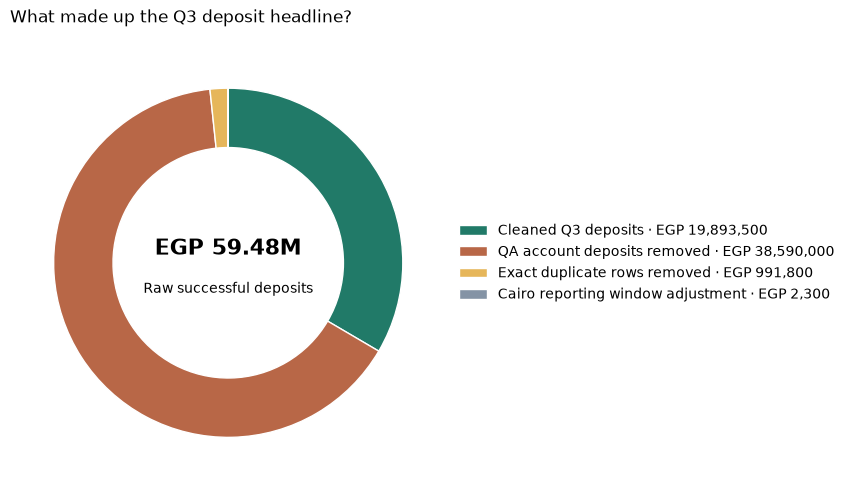

In [18]:
import matplotlib.pyplot as plt

audit_volume = deposit_audit.set_index("step")["volume_egp"]
raw_successful = audit_volume.loc[2]
after_deduplication = audit_volume.loc[3]
valid_users_utc = audit_volume.loc[4]

cleaned_q3 = pd.read_sql_query(
    """
    SELECT SUM(t.amount_egp) AS volume_egp
    FROM transactions AS t
    CROSS JOIN report_dates AS r
    WHERE t.txn_type = 'deposit'
      AND t.status = 'success'
      AND t.txn_cairo >= r.q3_start
      AND t.txn_cairo <  r.q3_end
    """,
    engine,
).at[0, "volume_egp"]

labels = [
    "Cleaned Q3 deposits",
    "QA account deposits removed",
    "Exact duplicate rows removed",
    "Cairo reporting window adjustment",
]
amounts = [
    cleaned_q3,
    after_deduplication - valid_users_utc,
    raw_successful - after_deduplication,
    valid_users_utc - cleaned_q3,
]
colors = ["#217A68", "#B86747", "#E6B65A", "#8493A5"]

fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
wedges, _ = ax.pie(
    amounts,
    colors=colors,
    startangle=90,
    counterclock=False,
    wedgeprops={"width": 0.34, "edgecolor": "white"},
)
ax.text(0, 0.08, f"EGP {raw_successful / 1e6:.2f}M",
        ha="center", va="center", fontsize=16, fontweight="bold")
ax.text(0, -0.15, "Raw successful deposits",
        ha="center", va="center", fontsize=10)
ax.set_title("What made up the Q3 deposit headline?", loc="left", pad=16)
ax.legend(
    wedges,
    [f"{label} · EGP {amount:,.0f}" for label, amount in zip(labels, amounts)],
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False,
)
plt.show()